# Lecture 7 — Class Exercise
## Part-to-Whole: Hierarchical Visualization

> **Push to:** `week07/lecture07_exercise.ipynb`


In [1]:
import pandas as pd
import plotly.express as px
import numpy as np

# Dataset: Global Energy Mix by Country and Source
df = pd.read_csv('../data/global_energy_mix.csv')

# Source type mapping — reuse from lecture
source_category = {
    'Coal': 'Fossil', 'Oil': 'Fossil', 'Natural Gas': 'Fossil',
    'Nuclear': 'Low-carbon', 'Hydro': 'Low-carbon',
    'Wind': 'Renewable', 'Solar': 'Renewable', 'Other Renewables': 'Renewable'
}
df['Source_Type'] = df['Source'].map(source_category)

print(f"Loaded: {len(df)} rows")
print(df.head(10))


Loaded: 103 rows
         Country         Region            Source  Share_pct     TWh  \
0  United States  North America              Coal         10  1015.0   
1  United States  North America               Oil         35  3220.0   
2  United States  North America       Natural Gas         34  3083.0   
3  United States  North America           Nuclear          9   798.0   
4  United States  North America             Hydro          3   339.0   
5  United States  North America              Wind          4   413.0   
6  United States  North America             Solar          3   325.0   
7  United States  North America  Other Renewables          2   229.0   
8          China           Asia              Coal         58  6929.1   
9          China           Asia               Oil         18  1620.0   

  Source_Type  
0      Fossil  
1      Fossil  
2      Fossil  
3  Low-carbon  
4  Low-carbon  
5   Renewable  
6   Renewable  
7   Renewable  
8      Fossil  
9      Fossil  


## Task 1 — Treemap: fossil fuel dependency by country

**What to build:** A treemap showing **fossil fuel TWh only**, broken down by Region → Country → Source (Coal / Oil / Natural Gas).

**Requirements:**
- Filter to fossil sources only before plotting
- Use `path=['Region', 'Country', 'Source']` for the hierarchy
- Colour encodes the fossil source type (Coal / Oil / Natural Gas) with a CVD-safe palette
- Show TWh values in labels — no percentages
- Grey out parent nodes (Region and Country level)
- Insight title naming which region or country is most fossil-dependent

> 💡 `df.loc[df['Source_Type'] == 'Fossil']`


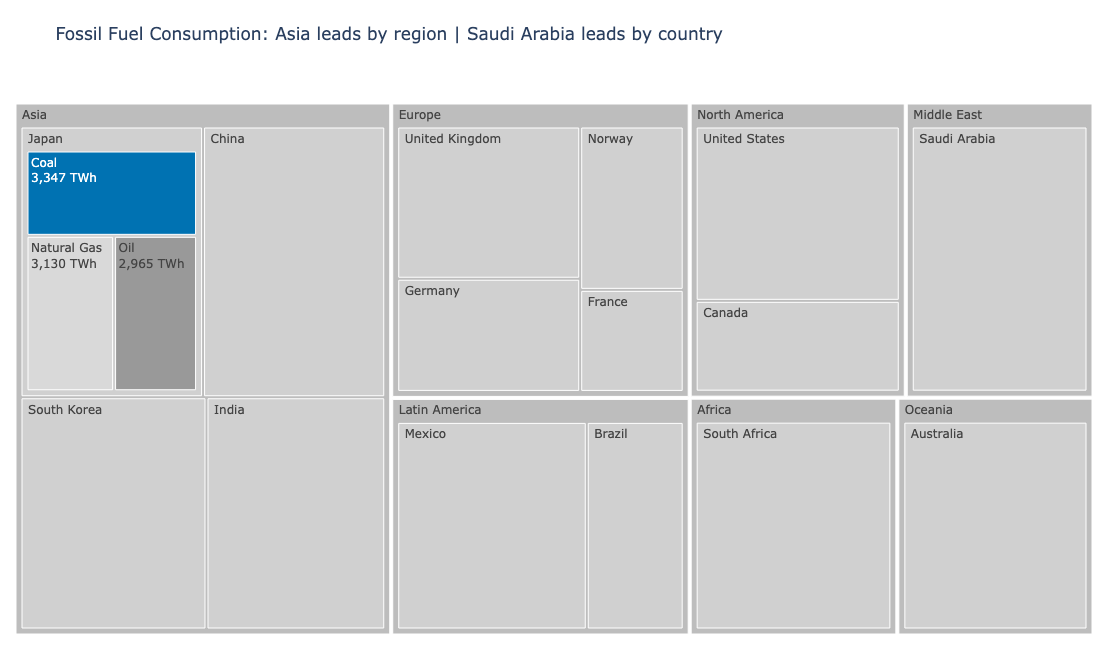

In [2]:
# Task 1

import plotly.graph_objects as go

# Filter fossil fuel sources only
df_fossil = df.loc[df['Source_Type'] == 'Fossil'].copy()

# Aggregate TWh by Region, Country and Source
treemap_data = (
    df_fossil.groupby(['Region', 'Country', 'Source'], as_index=False)['TWh']
    .sum()
)

# CVD-safe colour palette
source_colors = {
    'Coal': '#0072B2',
    'Oil': '#999999',
    'Natural Gas': '#D9D9D9'
}

# Create hierarchy
labels = []
parents = []
values = []
colors = []

# Region level
for region in treemap_data['Region'].unique():
    region_total = treemap_data.loc[
        treemap_data['Region'] == region, 'TWh'
    ].sum()

    labels.append(region)
    parents.append('')
    values.append(region_total)
    colors.append('#BDBDBD')

# Country level
for country in treemap_data['Country'].unique():
    country_data = treemap_data[treemap_data['Country'] == country]
    region = country_data['Region'].iloc[0]

    labels.append(country)
    parents.append(region)
    values.append(country_data['TWh'].sum())
    colors.append('#D0D0D0')

# Source level
for _, row in treemap_data.iterrows():
    labels.append(row['Source'])
    parents.append(row['Country'])
    values.append(row['TWh'])
    colors.append(source_colors[row['Source']])

# Create treemap
fig = go.Figure(go.Treemap(
    labels=labels,
    parents=parents,
    values=values,
    branchvalues='total',
    marker=dict(colors=colors),
    texttemplate='%{label}<br>%{value:,.0f} TWh',
    hovertemplate='%{label}<br>%{value:,.1f} TWh<extra></extra>',
    tiling=dict(packing='squarify')
))

# Find most fossil-dependent region and country by TWh
region_totals = treemap_data.groupby('Region')['TWh'].sum()
country_totals = treemap_data.groupby('Country')['TWh'].sum()

top_region = region_totals.idxmax()
top_country = country_totals.idxmax()

fig.update_layout(
    title=f'Fossil Fuel Consumption: {top_region} leads by region | {top_country} leads by country',
    margin=dict(t=80, l=10, r=10, b=10),
    height=650
)

fig.show()


## Task 2 — Treemap vs bar: low-carbon energy by country

**What to build:** Build **both** a treemap and a horizontal bar chart showing total low-carbon TWh (Nuclear + Hydro) per country. Then answer the question in a markdown cell below.

**Requirements:**
- Filter to `Source_Type == 'Low-carbon'` and aggregate TWh by country
- Treemap: single-level `path=['All', 'Country']` with a dummy root node labelled `'Low-carbon'`
- Bar chart: sorted by TWh, horizontal orientation, CVD-safe colour
- Both charts show TWh values, not percentages
- Insight title on the bar chart naming the leading country

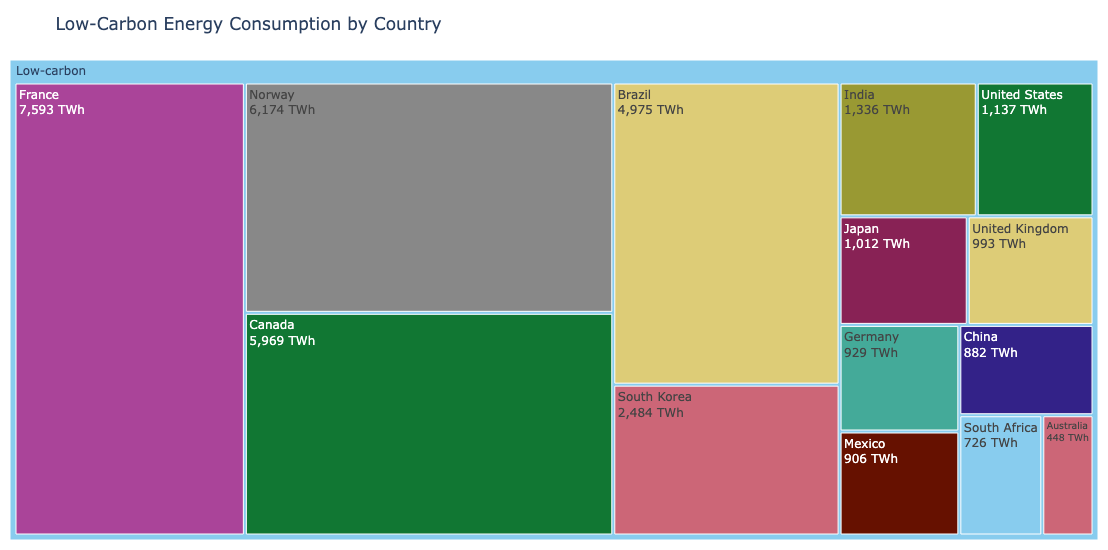

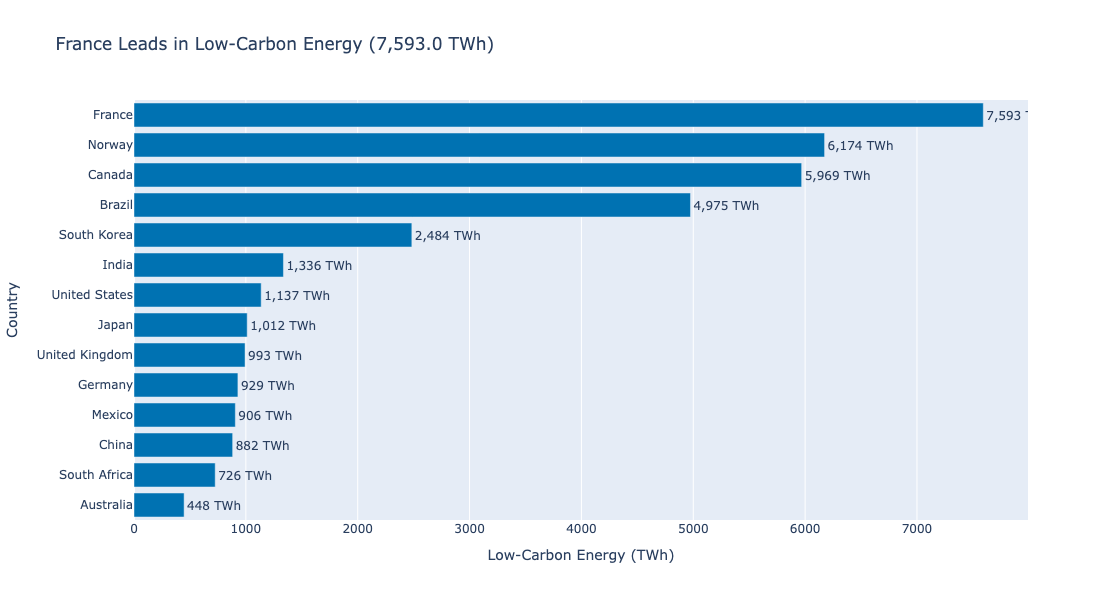

In [5]:

# Task 2 - Treemap vs Bar: Low-carbon energy by country

# Filter low-carbon sources
df_lowcarbon = df.loc[
    df['Source_Type'] == 'Low-carbon'
].copy()

# Aggregate TWh by country
lowcarbon_country = (
    df_lowcarbon.groupby('Country', as_index=False)['TWh']
    .sum()
    .sort_values('TWh', ascending=False)
)

# Create dummy root column
lowcarbon_country['All'] = 'Low-carbon'

# Find leading country
top_country = lowcarbon_country.iloc[0]['Country']
top_value = lowcarbon_country.iloc[0]['TWh']

# -------------------------------
# Chart 1: Treemap
# -------------------------------

fig1 = px.treemap(
    lowcarbon_country,
    path=['All', 'Country'],
    values='TWh',
    color='Country',
    color_discrete_sequence=px.colors.qualitative.Safe
)

fig1.update_traces(
    texttemplate='%{label}<br>%{value:,.0f} TWh',
    hovertemplate='%{label}<br>%{value:,.1f} TWh<extra></extra>'
)

fig1.update_layout(
    title='Low-Carbon Energy Consumption by Country',
    margin=dict(t=60, l=10, r=10, b=10),
    height=550
)

fig1.show()

# -------------------------------
# Chart 2: Horizontal Bar Chart
# -------------------------------

fig2 = px.bar(
    lowcarbon_country.sort_values('TWh', ascending=True),
    x='TWh',
    y='Country',
    orientation='h',
    text='TWh',
    color_discrete_sequence=['#0072B2'],
    title=f'{top_country} Leads in Low-Carbon Energy ({top_value:,.1f} TWh)'
)

fig2.update_traces(
    texttemplate='%{text:,.0f} TWh',
    textposition='outside'
)

fig2.update_layout(
    xaxis_title='Low-Carbon Energy (TWh)',
    yaxis_title='Country',
    showlegend=False,
    height=600
)

fig2.show()

### Task 2 — reflection

**Which chart tells the ranking story more clearly, and why?**

*YOUR ANSWER HERE*

The horizontal bar chart tells the ranking story more clearly because countries are arranged in order of their low-carbon energy consumption. It is easier to compare TWh values and identify the country with the highest and lowest consumption. The treemap is better for showing the relative contribution of each country to the overall low-carbon energy total.

## Task 3 — 100% stacked bar: which region relies most on coal?

**What to build:** A horizontal 100% stacked bar chart showing, for each **Region**, how its fossil energy splits between Coal, Oil and Natural Gas. This is the **same data as your Task 1 treemap**, visualised a second way.

**Requirements:**
- Reuse `df_fossil` from Task 1; aggregate TWh by `Region` × `Source` and convert to **shares of each region's fossil total**
- Horizontal bars, regions **sorted by coal share** (highest at the top)
- Coal is the segment on the baseline (first in `category_orders`) and the **only coloured segment** — keep it the same colour as in Task 1; Oil and Natural Gas in two greys
- Percentage labels on the coal segments only
- Insight title naming the most coal-dependent region and its coal share

> 💡 `df.groupby('Region')['TWh'].transform('sum')` gives each row its region total

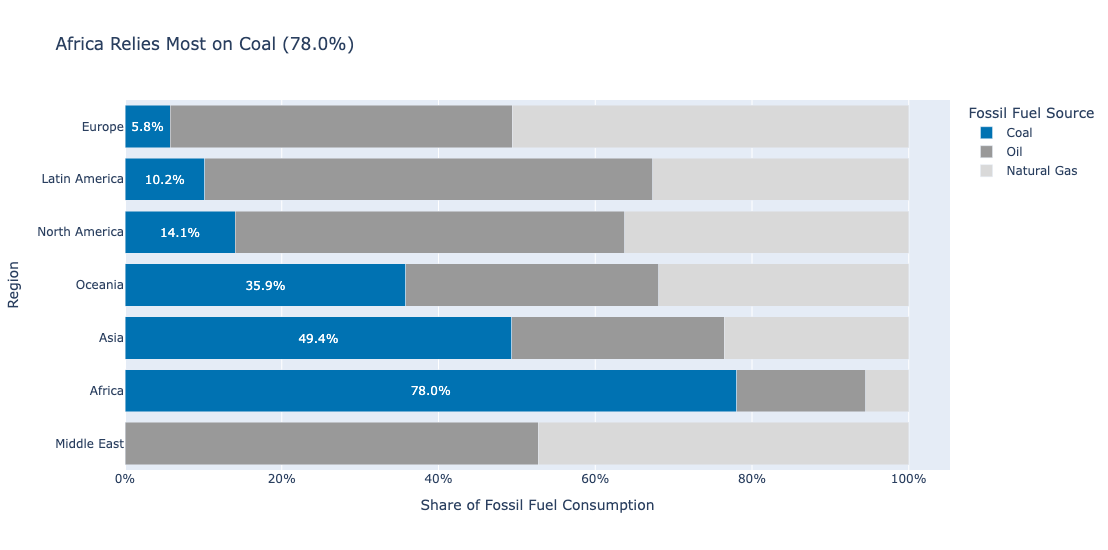

In [3]:
# Task 3

# Aggregate fossil fuel TWh by Region and Source
region_source = (
    df_fossil.groupby(['Region', 'Source'])['TWh']
    .sum()
    .reset_index()
)

# Calculate each region's total fossil fuel consumption
region_source['Region_Total'] = (
    region_source.groupby('Region')['TWh'].transform('sum')
)

# Calculate percentage share
region_source['Share'] = (
    region_source['TWh'] / region_source['Region_Total']
)

# Calculate coal share for sorting
coal_shares = (
    region_source[region_source['Source'] == 'Coal']
    .set_index('Region')['Share']
)

# Sort regions by coal share, highest first
region_order = coal_shares.sort_values(ascending=False).index.tolist()

# Colour palette - same as Task 1
source_colors = {
    'Coal': '#0072B2',
    'Oil': '#999999',
    'Natural Gas': '#D9D9D9'
}

# Create percentage labels only for Coal
region_source['Coal_Label'] = region_source.apply(
    lambda row: f"{row['Share']:.1%}"
    if row['Source'] == 'Coal' else '',
    axis=1
)

# Create stacked bar chart
fig = px.bar(
    region_source,
    x='Share',
    y='Region',
    color='Source',
    orientation='h',
    text='Coal_Label',
    color_discrete_map=source_colors,
    category_orders={
        'Region': region_order,
        'Source': ['Coal', 'Oil', 'Natural Gas']
    },
    title='Which Region Relies Most on Coal?'
)

# Make bars 100% stacked
fig.update_layout(
    barmode='stack',
    xaxis=dict(
        tickformat='.0%',
        title='Share of Fossil Fuel Consumption'
    ),
    yaxis=dict(
        title='Region',
        autorange='reversed'
    ),
    legend_title='Fossil Fuel Source',
    height=550
)

# Show percentage labels on Coal segments only
fig.update_traces(
    textposition='inside',
    insidetextanchor='middle'
)

# Find the most coal-dependent region
top_coal_region = coal_shares.idxmax()
top_coal_share = coal_shares.max()

fig.update_layout(
    title=f'{top_coal_region} Relies Most on Coal ({top_coal_share:.1%})'
)

fig.show()


### Task 3 — reflection

**Your Task 1 treemap and this stacked bar show the same fossil data. Name one question each chart answers that the other cannot.**

*YOUR ANSWER HERE*
The treemap shows which countries and regions consume the largest amounts of fossil fuels and how Coal, Oil and Natural Gas contribute to their total consumption. The 100% stacked bar chart shows which region has the highest percentage of coal dependency and compares the proportion of each fossil fuel source across regions. Therefore, the treemap is better for comparing absolute TWh values, while the stacked bar chart is better for comparing relative fuel shares.